# PHM 2015 | Numerical Representation and Historical Cases

**Question.** How should numerical features within each case be represented so that the classifier can distinguish the recorded event types?

Represent a case with a fixed set of interpretable descriptors, then learn the numerical transformation on training sites. Preserve component-level extremes, describe the recent part of the window, and retain measurement quality. A classifier can learn curved effects through a spline basis. For historical retrieval, compare standardised descriptors with balanced weights across channel groups.

| Representation | Contents | Purpose |
| --- | --- | --- |
| Native case record | Levels, IQRs, changes, recent values, slopes, persistence and coverage | Inspect the evidence and explain comparisons |
| Classifier input | Training-fitted clipping, imputation, redundancy removal, curved terms and scaling | Estimate the three class scores |
| Retrieval vector | The retained descriptors, standardised and weighted by group | Find similar training cases with known outcomes |

The earlier [EDA notebook](eda_case_design.ipynb) motivated this comparison. This notebook tests six declared representations on the reserved validation sites, saves the selected classifier, and builds a callable numerical case system. The [version record](version_history/v0.3.0_case_representation.md) explains the implementation and its limits.

## 1. Declare the Comparison Before Reading Validation Outcomes

All six candidates use the same training cases, validation sample, clipping percentiles, L2 penalty, class-balancing policy, and feature-screening rule. The comparison crosses three feature sets with linear or curved effects. Select the highest validation macro-F1. Candidates within 0.005 of that score prefer fewer coefficients, then lower log loss. This is the representation-selection stage of the experiment.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
import hashlib
import json
import platform
import sys

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import JSON, Markdown, display
from scipy.special import softmax
from sklearn.metrics import confusion_matrix, classification_report, f1_score
get_ipython().run_line_magic("matplotlib", "inline")

project = Path.cwd().resolve()
if (project / "Files" / "phm_case_system.py").is_file():
    project = project / "Files"
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
import phm_case_design as design
import phm_case_system as system

folder = project.parent / "Datasets" / "PHM15-prepared"
source = folder / "case_inputs.duckdb"
prior = folder / "case_design.duckdb"
destination = folder / "case_system.duckdb"
figures = folder / "case_system_figures"
figures.mkdir(exist_ok=True)
scratch = TemporaryDirectory(prefix="case-system-", dir=folder)
staged = Path(scratch.name) / destination.name
db = duckdb.connect(str(staged), config={"threads": 1, "memory_limit": "256MB"})
design.save_frame(db, "selection_protocol", pd.DataFrame([{"protocol_json": json.dumps(system.PROTOCOL)}]))
system.attach_views(db, source)
started = perf_counter()
pd.set_option("display.max_colwidth", 85)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
labels = list(system.LABELS)

def show_figure(figure, filename):
    figure.savefig(figures / filename, dpi=170, bbox_inches="tight")
    display(figure)
    plt.close(figure)

display(JSON(system.PROTOCOL, expanded=False))
print(f"Kernel {sys.executable}")

<IPython.core.display.JSON object>

Kernel C:\Users\ges2j\OneDrive\Desktop\Assessments\CP5403\Files\.venv\Scripts\python.exe


## 2. Retain the Existing Training Cohort and Create Validation Cases

The training cohort comes from the retained v0.2 cases. Validation uses the same seeded episode sampling, cap of 30 cases per site and class, three-hour spacing, and 0.75 component-fraction rule. The ten validation sites supply the representation comparison. The ten test sites are reserved for frozen evaluation.

Only the selected three-hour windows are materialised, one site at a time. The source measurement database is attached read-only. Its private event labels determine scoring eligibility. Numerical feature extraction reads component measurements.

In [2]:
with duckdb.connect(str(prior), read_only=True) as previous:
    train = previous.execute('''select * from case_features join private_case_scores using(case_id)
        order by site_id,decision_time''').df()
assert len(train) == 3308
train = train.merge(system.augment_points(db, train, "train"), on="case_id", validate="one_to_one")
system.save_features(db, "private_training_cases", train)

points, sampling = design.select_scout_points(db, prefix="validation")
base, provenance = design.aggregate_scout_points(db, points, prefix="validation")
validation = points.merge(base, on="case_id", validate="one_to_one").merge(
    provenance, on="case_id", validate="one_to_one")
validation = validation[(validation.usable_component_fraction >= 0.75) &
                        (validation.recent_component_fraction >= 0.75)].copy()
validation = validation.merge(system.augment_points(db, validation, "validation"),
                              on="case_id", validate="one_to_one")
system.save_features(db, "private_validation_cases", validation)
design.save_frame(db, "validation_sampling_audit", sampling)
display(pd.concat({"train": train.groupby("reference_label").size(),
                   "validation": validation.groupby("reference_label").size()}, axis=1).reindex(labels))
display(Markdown(f"The representation comparison uses **{len(train):,} training cases** from "
    f"**{train.site_id.nunique()} sites** and **{len(validation):,} validation cases** from "
    f"**{validation.site_id.nunique()} sites**. The cohorts retain their deliberate sampling scheme."))

Extended train features for 369 cases


Extended train features for 631 cases


Extended train features for 910 cases


Extended train features for 1287 cases


Extended train features for 1510 cases


Extended train features for 1850 cases


... (15 outputs left out)

Extended validation features for 325 cases


Extended validation features for 638 cases


,train,validation
reference_label,,
NoRecordedTarget,1375,299
RuntimeExcessive,1088,187
SupplyTempTooCold,845,242


The representation comparison uses **3,308 training cases** from **46 sites** and **728 validation cases** from **10 sites**. The cohorts retain their deliberate sampling scheme.

## 3. Make the Features Describe What Is Happening Near the Decision

| Feature family | Definition | Reason to include it |
| --- | --- | --- |
| Overall level and extremes | Typical, lowest and highest qualifying component median | Preserve both common behaviour and a potentially affected unit |
| Variation and change | Typical component IQR and last-minus-first change | Describe fluctuation and direction over the full window |
| Recent level | Component medians within the last hour, then their typical and extreme values | Avoid averaging a recent change across all three hours |
| Early-to-recent change | Last-hour median minus first-hour median within a component, then median across components | Compare the end of the window with its beginning |
| Slope | Within-component least-squares slope against actual observation time, in native units per hour | Use all valid readings when describing a trend |
| Persistence | Mean channel 3 transition rate and longest uninterrupted same-code run divided by twelve | Represent duration and switching without ordering the codes |
| Coverage and state | Component fractions, bin coverage, recent usable-component fraction, occupied and setback proportions | Describe measurement support and operating context |

Temporal descriptors use channels 1, 2, and 5. The first and last hour each need at least two valid bins for their contrast, and a component needs eight bins across the complete window. A missing quarter hour interrupts a same-code run.

The category-frequency sensitivity learns up to five common values per code channel from the fitting cases. It represents fractions of time at each code, averages components equally, omits the most frequent reference category, and combines remaining values in an other-category fraction. This avoids assigning a physical ordering to the code numbers. Their domain meanings remain unverified.

In [3]:
display(train[["ch1_recent_lowest_component_median", "ch2_early_to_recent_change",
    "ch2_median_component_slope_per_hour", "ch3_mean_transition_rate",
    "ch3_mean_longest_run_fraction", "recent_usable_component_fraction"]].describe().round(3))
display(pd.DataFrame({"missing_fraction": train[system.TEMPORAL_FEATURES].isna().mean()}).round(4))

,ch1_recent_lowest_component_median,ch2_early_to_recent_change,ch2_median_component_slope_per_hour,ch3_mean_transition_rate,ch3_mean_longest_run_fraction,recent_usable_component_fraction
count,3308.000,3308.000,3308.000,3308.000,3308.000,3308.000
mean,715.138,-4.932,-2.598,0.173,0.649,0.999
std,27.334,37.709,18.064,0.121,0.162,0.013
min,469.500,-308.000,-134.802,0.000,0.222,0.750
25%,708.000,-12.000,-5.996,0.074,0.528,1.000
50%,720.000,-4.000,-2.009,0.163,0.636,1.000
75%,728.000,4.500,2.577,0.248,0.778,1.000
max,797.000,230.500,109.914,0.614,1.000,1.000


,missing_fraction
ch1_recent_component_median,0.0
ch1_recent_lowest_component_median,0.0
ch1_recent_highest_component_median,0.0
ch1_early_to_recent_change,0.0
ch1_median_component_slope_per_hour,0.0
ch2_recent_component_median,0.0
ch2_recent_lowest_component_median,0.0
ch2_recent_highest_component_median,0.0
ch2_early_to_recent_change,0.0
ch2_median_component_slope_per_hour,0.0


## 4. Fit the Numerical Representation on Training Data

Clip each numerical descriptor at its training 0.5th and 99.5th percentiles, impute training medians, and remove constants and strongly redundant pairs. The curved variant adds a cubic spline basis to continuous levels and trends. Proportions retain their direct representation. Standardise the resulting model coordinates before fitting the regularised multinomial logistic model.

Spline knots, category vocabulary, clipping bounds, imputation values, retained features, and scaling parameters are fitted on the training cases. Spline extrapolation is held constant outside its fitted range. Native feature values and preparation flags remain available in the evidence record. [Spline basis documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html), [scaling and categorical encoding](https://scikit-learn.org/stable/modules/preprocessing.html)

Validated summary_linear


Validated summary_spline


Validated temporal_linear


Validated temporal_spline


Validated temporal_codes_linear


Validated temporal_codes_spline


,candidate,macro_f1,log_loss,runtime_recall,supply_recall,coefficients_per_class,iterations,fit_and_score_seconds
0,summary_linear,0.5738,0.9086,0.7273,0.4628,19,16,0.6642
1,summary_spline,0.5819,0.8739,0.5615,0.6033,79,145,0.8944
2,temporal_linear,0.6157,0.8453,0.7594,0.5207,31,53,0.3288
3,temporal_spline,0.6453,0.7876,0.6952,0.6364,127,182,0.6617
4,temporal_codes_linear,0.6159,0.8349,0.5829,0.5950,44,59,0.4249
5,temporal_codes_spline,0.6242,0.8844,0.5722,0.6364,140,179,1.6659


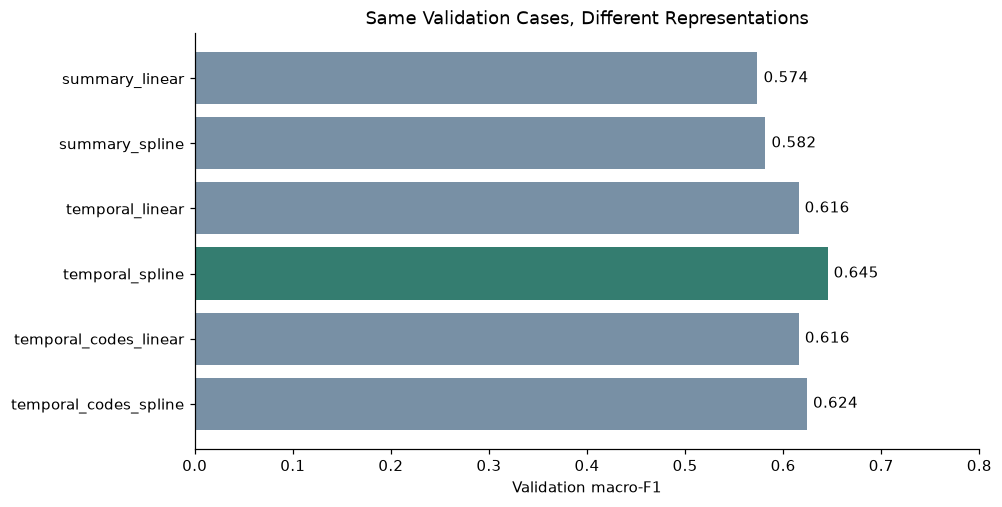

The declared rule selects **temporal_spline** with macro-F1 **0.645**. The summary-only linear model reaches **0.574** on these same cases. SupplyTempTooCold recall changes from **46.3%** to **63.6%**.

In [4]:
metrics, predictions, winner, model = system.compare_representations(train, validation)
design.save_frame(db, "validation_metrics", metrics)
design.save_frame(db, "validation_predictions", predictions)
display(metrics.round(4))
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
colours = ["#347d70" if name == winner else "#7890a5" for name in metrics.candidate]
bars = ax.barh(metrics.candidate, metrics.macro_f1, color=colours)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set(xlim=(0, 0.8), xlabel="Validation macro-F1", title="Same Validation Cases, Different Representations")
ax.invert_yaxis()
show_figure(fig, "01_representation_comparison.png")
baseline = metrics.set_index("candidate").loc["summary_linear"]
selected = metrics.set_index("candidate").loc[winner]
display(Markdown(f"The declared rule selects **{winner}** with macro-F1 **{selected.macro_f1:.3f}**. "
    f"The summary-only linear model reaches **{baseline.macro_f1:.3f}** on these same cases. "
    f"SupplyTempTooCold recall changes from **{baseline.supply_recall:.1%}** to **{selected.supply_recall:.1%}**."))

## 5. Inspect Which Fault Distinctions Improve

Compare the same recorded outcomes with the baseline and selected predictions. Validation results guide this model choice. Their performance estimate includes that selection and will need the later frozen test.

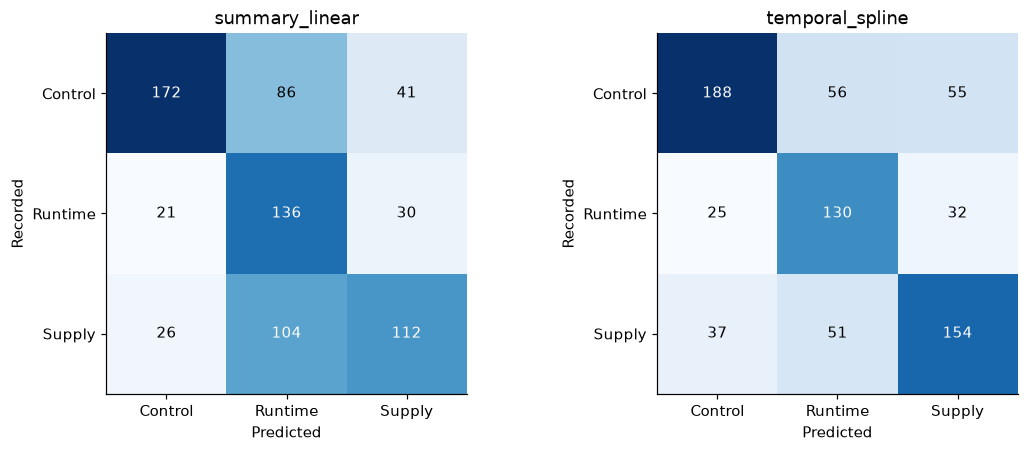

,precision,recall,f1-score,support
NoRecordedTarget,0.752,0.629,0.685,299.000
RuntimeExcessive,0.549,0.695,0.613,187.000
SupplyTempTooCold,0.639,0.636,0.638,242.000
accuracy,0.648,0.648,0.648,0.648
macro avg,0.647,0.653,0.645,728.000
weighted avg,0.662,0.648,0.651,728.000


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, candidate in zip(axes, ["summary_linear", winner]):
    scored = predictions[predictions.candidate == candidate].merge(
        validation[["case_id", "reference_label"]], on="case_id", validate="one_to_one")
    matrix = confusion_matrix(scored.reference_label, scored.prediction, labels=labels)
    ax.imshow(matrix, cmap="Blues")
    ax.set(xticks=range(3), xticklabels=["Control", "Runtime", "Supply"],
           yticks=range(3), yticklabels=["Control", "Runtime", "Supply"],
           xlabel="Predicted", ylabel="Recorded", title=candidate)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                    color="white" if matrix[i,j] > matrix.max()/2 else "black")
show_figure(fig, "02_validation_confusions.png")
selected_predictions = predictions[predictions.candidate == winner].merge(
    validation[["case_id", "reference_label"]], on="case_id", validate="one_to_one")
display(pd.DataFrame(classification_report(selected_predictions.reference_label,
    selected_predictions.prediction, labels=labels, output_dict=True, zero_division=0)).T.round(3))

## 6. Build the Historical Bank and Retain Model Parameters

Historical cases come from the training cohort. Their diagnostic class scores are generated through five whole-site folds, so a site's historical score comes from a model fitted on other training sites. The selected model fitted to all training cases supplies scores for new queries.

The coefficients belong to the fitted classifier. With curved effects, their coordinates are spline basis terms plus directly represented proportions. The case carries native descriptors and its three class scores. The stored model reproduces the complete transformation.

For case $i$ and class $k$, the model computes

$$s_{ik}=b_k+\boldsymbol{\beta}_k^T\phi(\mathbf{x}_i),\qquad p_{ik}=\frac{\exp(s_{ik})}{\sum_j\exp(s_{ij})}.$$

Here $\mathbf{x}_i$ contains the case descriptors, $\phi$ is the saved preparation and basis transformation, and $b_k$ and $\boldsymbol{\beta}_k$ are shared fitted parameters. The three $p_{ik}$ values are the case-specific class scores. The later validation cell reconstructs this calculation explicitly.


In [6]:
oof, folds = system.cross_fitted_scores(train, winner)
design.save_frame(db, "training_oof_scores", oof)
design.save_frame(db, "training_folds", folds)
bank = system.CaseSystem(model, winner, train, oof)
terms = model[:-1].get_feature_names_out()
parameter_rows = []
for i, label in enumerate(model[-1].classes_):
    parameter_rows.append((label, "(intercept)", float(model[-1].intercept_[i])))
    parameter_rows.extend((label, term, float(value)) for term, value in zip(terms, model[-1].coef_[i]))
parameters = pd.DataFrame(parameter_rows, columns=["class", "model_coordinate", "coefficient"])
design.save_frame(db, "selected_model_parameters", parameters)
schema = pd.DataFrame({"feature": bank.features, "group": [system.feature_group(f) for f in bank.features],
                       "retrieval_weight": bank.weights})
design.save_frame(db, "feature_schema", schema)
display(schema)
display(Markdown(f"The selected representation retains **{len(bank.features)} descriptors** for case comparison "
    f"and expands to **{model[-1].coef_.shape[1]} classifier coordinates per class**."))

,feature,group,retrieval_weight
0,ch1_median_of_component_medians,ch1,0.154303
1,ch1_median_of_component_iqrs,ch1,0.154303
2,ch1_median_of_component_changes,ch1,0.154303
3,ch1_lowest_component_median,ch1,0.154303
4,ch1_highest_component_median,ch1,0.154303
5,ch2_median_of_component_medians,ch2,0.129099
6,ch2_median_of_component_iqrs,ch2,0.129099
7,ch2_median_of_component_changes,ch2,0.129099
8,ch2_lowest_component_median,ch2,0.129099
9,ch2_highest_component_median,ch2,0.129099


The selected representation retains **31 descriptors** for case comparison and expands to **127 classifier coordinates per class**.

## 7. Retrieve Three Historical Analogues

Use the classifier's retained descriptors before spline expansion. Apply training-fitted scaling and weight each coordinate by 1 / sqrt(number of coordinates in its group × number of groups). Euclidean distance then balances channel groups, coverage, and operating state. Each query returns at most one case per historical site. A known query site's own cases are excluded.

The distance uses measurements and coverage. Labels and classifier scores are attached as evidence or used for evaluation afterward. The nearest cases supply comparisons for the eventual case-based reasoning step. [Nearest-neighbour methods](https://scikit-learn.org/stable/modules/neighbors.html)

,queries,matching_label_in_top_three
reference_label,,
NoRecordedTarget,299,0.836
RuntimeExcessive,187,0.909
SupplyTempTooCold,242,0.769


The top three contain a matching recorded outcome for **83.2%** of validation queries. A neighbour-majority vote reaches macro-F1 **0.584**. Median retrieval time is **16.4 ms**, excluding feature extraction. Label agreement is a retrieval proxy. Inspect the actual numerical comparison before treating an analogue as useful evidence.

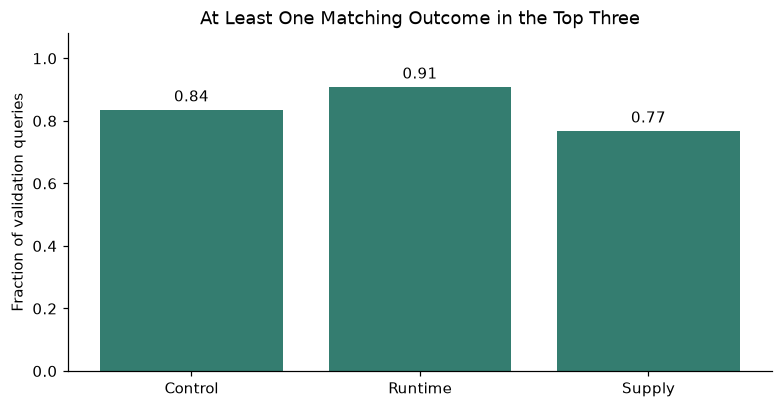

In [7]:
links, retrieval = system.retrieval_audit(bank, validation)
design.save_frame(db, "retrieval_links", links)
design.save_frame(db, "private_retrieval_evaluation", retrieval)
retrieval_summary = retrieval.groupby("reference_label").agg(
    queries=("case_id", "size"), matching_label_in_top_three=("hit_at_3", "mean")).reindex(labels)
display(retrieval_summary.round(3))
vote_f1 = f1_score(retrieval.reference_label, retrieval.neighbour_vote, average="macro")
display(Markdown(f"The top three contain a matching recorded outcome for **{retrieval.hit_at_3.mean():.1%}** "
    f"of validation queries. A neighbour-majority vote reaches macro-F1 **{vote_f1:.3f}**. "
    f"Median retrieval time is **{retrieval.seconds.median()*1000:.1f} ms**, excluding feature extraction. "
    "Label agreement is a retrieval proxy. Inspect the actual numerical comparison before treating an analogue as useful evidence."))
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
bars = ax.bar(["Control", "Runtime", "Supply"], retrieval_summary.matching_label_in_top_three, color="#347d70")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(ylim=(0, 1.08), ylabel="Fraction of validation queries", title="At Least One Matching Outcome in the Top Three")
show_figure(fig, "03_retrieval_label_coverage.png")

## 8. Produce a Case Record From Measurements

The ordinary query entry point takes a site and quarter-hour decision time. It reads the component table, checks trailing-window coverage, computes descriptors, and returns numerical evidence. It can operate without consulting the event or eligibility tables.

The evidence record contains an opaque ID, native feature values, measurement quality, preparation flags, model scores, and historical cases with known outcomes. The comparisons identify a close numerical feature and a large difference. Standardised gaps are computed after clipping and imputation, while displayed feature values retain their native values.

In [8]:
example = validation.sort_values("case_id").iloc[0]
with duckdb.connect(str(source), read_only=True) as measurements:
    query, reason = system.query_from_measurements(measurements, int(example.site_id), example.decision_time)
assert reason is None
record = bank.evidence(query, site_id=int(example.site_id))
json.dumps(record, allow_nan=False)
display(JSON(record, expanded=False))
display(pd.DataFrame([{"historical_case_id": c["case_id"], "recorded_outcome": c["recorded_outcome"],
    "distance": c["distance"], "largest_gap_feature": c["comparison"][1]["feature"]}
    for c in record["historical_cases"]]))
display(Markdown(f"For this private audit, the query's recorded outcome is **{example.reference_label}**. "
    "The query payload above obtains its class evidence from measurements, the fitted model, and historical cases."))
design.save_frame(db, "example_evidence", pd.DataFrame([{"case_id": record["case_id"],
    "evidence_json": json.dumps(record, allow_nan=False)}]))

<IPython.core.display.JSON object>

,historical_case_id,recorded_outcome,distance,largest_gap_feature
0,a750d9956d85587bb58a63c9b1cbe7a7,NoRecordedTarget,0.474853,ch1_lowest_component_median
1,44746720bd075d15a145408512baa6a0,SupplyTempTooCold,0.534552,ch1_lowest_component_median
2,ade12f0ec9aa532b9e4f4d6a99ecdee0,RuntimeExcessive,0.634402,ch1_median_of_component_iqrs


For this private audit, the query's recorded outcome is **RuntimeExcessive**. The query payload above obtains its class evidence from measurements, the fitted model, and historical cases.

## 9. Validate and Publish the Numerical Case System

Checks cover site isolation, episode uniqueness, time boundaries, reference-label alignment, neighbour diversity, complete out-of-fold scoring, valid code proportions, and invariance to a changed private query label. The model and historical bank are stored together inside one database artifact. The saved contract records the selection protocol, source fingerprints, code fingerprints, and environment.

In [9]:
checks = system.validate_system(db, bank, validation, links, oof, folds)
for check in checks:
    print(check)
prepared_query = model[:-1].transform(query)
rebuilt = softmax(prepared_query @ model[-1].coef_.T + model[-1].intercept_, axis=1)
assert np.allclose(rebuilt, model.predict_proba(query))
system.persist_system(db, bank)
contract = dict(system.PROTOCOL)
contract.update(selected_candidate=winner, training_cases=len(train), validation_cases=len(validation),
    native_descriptors=len(bank.features), classifier_coordinates=model[-1].coef_.shape[1],
    python=platform.python_version(), sklearn=sklearn.__version__, pandas=pd.__version__,
    numpy=np.__version__, duckdb=duckdb.__version__)
contract["input_sha256"] = {}
for path in (source, prior):
    with path.open("rb") as handle:
        contract["input_sha256"][path.name] = hashlib.file_digest(handle, "sha256").hexdigest()
contract["code_sha256"] = {}
for name in ("phm_case_system.py", "phm_case_design.py", "phm_case_samples.py", "phm_preprocessing.py"):
    contract["code_sha256"][name] = hashlib.sha256((project / name).read_bytes()).hexdigest()
design.save_frame(db, "case_system_contract", pd.DataFrame([{"contract_json": json.dumps(contract)}]))
db.close()
staged.replace(destination)
scratch.cleanup()
loaded = system.load_system(destination)
assert np.array_equal(loaded.model.predict_proba(query), model.predict_proba(query))
assert loaded.evidence(query, int(example.site_id)) == record
print(f"Saved {destination}")
print(f"{destination.stat().st_size/2**20:.1f} MiB | {(perf_counter()-started)/60:.1f} minutes")

Training and Validation Site Isolation
Unique Episodes and Non-Overlapping Cases
Actual Observation Time Boundaries
Labels Match the Eligible Decision Table
Three Historical Cases From Distinct Training Sites
Same-Site Exclusion for Large Retrieval Requests
Complete Grouped Out-of-Fold Scores
Finite Class Scores Sum to One
Private Query Labels Do Not Affect Prediction or Retrieval
Code Profiles Are Valid Proportions


Saved C:\Users\ges2j\OneDrive\Desktop\Assessments\CP5403\Datasets\PHM15-prepared\case_system.duckdb
7.5 MiB | 3.6 minutes


## 10. Answer and Handoff

The validation evidence supports describing each case with component level and extremes, robust variation, recent movement, persistence, and coverage. Train-fitted scaling makes these quantities comparable. Curved effects improve the selected classifier's use of those descriptors. The raw-code-frequency expansion remains a documented sensitivity result.

For explanation and case comparison, retain the native values and flag clipping or imputation. For model inference, reuse the saved transformation. For retrieval, reuse the frozen training bank and its weighted standardised descriptor space.

The database now supports a new site/time query returning three class scores and three historical analogues. The remaining case-based reasoning layer can compare those records and cite their IDs. Overlapping class distributions, incomplete event recording, uncertain physical channel meanings, and sampling-dependent score calibration continue to limit the strength of a diagnosis. The final test and the contribution of an LLM or literature retrieval still require their planned evaluation.

In [10]:
# Query the Saved System
case_system = system.load_system(destination)
with duckdb.connect(str(source), read_only=True) as measurements:
    next_query, reason = system.query_from_measurements(
        measurements, int(example.site_id), example.decision_time)
if reason:
    print(reason)
else:
    evidence = case_system.evidence(next_query, site_id=int(example.site_id))
    display(pd.Series(evidence["class_scores"], name="class_score").to_frame())
    print(f"Retrieved {len(evidence['historical_cases'])} historical cases")

,class_score
NoRecordedTarget,0.177324
RuntimeExcessive,0.584229
SupplyTempTooCold,0.238447


Retrieved 3 historical cases
